## Load reciprocal best blast hits

In [2]:

%%bash
cd ncbi_dataset/data/GCA_965233325.1
singularity exec /cvmfs/singularity.galaxyproject.org/g/f/gffread:0.12.9--hf426362_0 gffread braker.gtf -g *.fna -x cds.faa

In [3]:
import pandas as pd

rbb_df=pd.read_csv("outputs/impatiens_v_coprophila_reciprocal_best_blast_results.csv",index_col=0)
rbb_df

,Bcopro_prot,impatiens_prot
0,XP_037044609.1,bimpatiensg23840.t1
1,XP_037038352.1,bimpatiensg15641.t2
2,XP_037033747.1,bimpatiensg17223.t1
3,XP_037042026.1,bimpatiensg15696.t1
4,XP_037042318.1,bimpatiensg15438.t1
...,...,...
13041,XP_037031244.1,bimpatiensg15120.t1
13042,XP_037041936.1,bimpatiensg24830.t1
13043,XP_080116807.1,bimpatiensg18270.t1
13044,XP_080112729.1,bimpatiensg26131.t1


In [4]:
rbb_map={x:y for x,y in zip(rbb_df.Bcopro_prot,rbb_df.impatiens_prot)}

## Obtain dnds for rbbs 

In [3]:
from Bio import SeqIO
import pandas as pd
from Bio import SearchIO
import os
import multiprocessing as mp

In [11]:
%%bash
wget https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/016/920/775/GCA_016920775.1_B2019C/GCA_016920775.1_B2019C_cds_from_genomic.fna.gz
gunzip GCA_016920775.1_B2019C_cds_from_genomic.fna.gz
mv GCA_016920775.1_B2019C_cds_from_genomic.fna ncbi_dataset/data/GCA_016920775.1/GCA_016920775.1_B2019C_cds_from_genomic.fna

--2026-07-04 15:31:34--  https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/016/920/775/GCA_016920775.1_B2019C/GCA_016920775.1_B2019C_cds_from_genomic.fna.gz
Resolving ftp.ncbi.nlm.nih.gov... 130.14.250.11, 130.14.250.12, 2607:f220:41e:250::7, ...
Connecting to ftp.ncbi.nlm.nih.gov|130.14.250.11|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 8174742 (7.8M) [application/x-gzip]
Saving to: ‘GCA_016920775.1_B2019C_cds_from_genomic.fna.gz’

     0K .......... .......... .......... .......... ..........  0% 2.11M 4s
    50K .......... .......... .......... .......... ..........  1% 63.7M 2s
   100K .......... .......... .......... .......... ..........  1% 3.84M 2s
   150K .......... .......... .......... .......... ..........  2% 90.2M 1s
   200K .......... .......... .......... .......... ..........  3% 3.90M 2s
   250K .......... .......... .......... .......... ..........  3% 90.9M 1s
   300K .......... .......... .......... .......... ..........  4%  128M 1s
   350

In [6]:
input_file = open(f"ncbi_dataset/data/GCA_965233325.1/protein.faa")
bo_fastap = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
# input_file=open(f"ncbi_dataset/data/GCA_965233325.1/cds.faa")
bo_fastan = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

In [15]:
bo_fastan2={}
for x in bo_fastan:
    bo_fastan2["bimpatiens"+x]=bo_fastan[x]
bo_fastan=bo_fastan2

In [28]:
input_file = open(f"ncbi_dataset/data/GCF_014529535.2/protein.faa")
bc_fastap = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
input_file=open(f"ncbi_dataset/data/GCF_014529535.2/GCF_014529535.2_BU_Bcop_v2.1_cds_from_genomic.fna")
bc_fastan = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

In [17]:
!mkdir pairwise_copro_impatiens_dnds

In [32]:
## for each rbb pair g, align protein seqs with muscle, obtain codon alignments from cds seqs with pal2nal, then run paml M0
def run_paml_pipe(g):

    go=rbb_map[g]

    !mkdir -p pairwise_copro_impatiens_dnds/$g

    ##write protein fasta
    f=open(f'pairwise_copro_impatiens_dnds/{g}/protein_fasta.fa','w')
    f.write(f'>{g}\n')
    f.write(str(bc_fastap[g].seq)+"\n")
    f.write(f'>{go}\n')
    f.write(str(bo_fastap[go].seq)+"\n")
    f.close()

    ##align protein seqs
    !singularity exec /cvmfs/singularity.galaxyproject.org/m/u/muscle:5.1--h9f5acd7_2 muscle -align pairwise_copro_impatiens_dnds/$g/protein_fasta.fa -output pairwise_copro_impatiens_dnds/$g/ali_prot.fasta

    ##write nucleotide fasta 
    input_file = open(f"pairwise_copro_impatiens_dnds/{g}/ali_prot.fasta")
    fa = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

    a=list(fa.keys())
    f=open(f'pairwise_copro_impatiens_dnds/{g}/nuc_fasta.fa','w')
    for ai in a:
        if "XP_" in ai:
            l=bc_fastan.keys()
            k=[x for x in l if ai in x][0]
            f.write(f">{ai}\n")
            f.write(str(bc_fastan[k].seq)+"\n")
        else:
            l=bo_fastan.keys()
            k=[x for x in l if ai in x][0]
            f.write(f">{ai}\n")
            f.write(str(bo_fastan[k].seq)+"\n")
    f.close()

    ##write newick tree
    f=open(f'pairwise_copro_impatiens_dnds/{g}/tree.newick','w')
    a=tuple(a)
    f.write(str(a).replace("'","")+";")
    f.close()

    ##run pal2nal to get codon alignment
    !singularity exec /cvmfs/singularity.galaxyproject.org/p/a/pal2nal:14.1--pl526_0 pal2nal.pl  pairwise_copro_impatiens_dnds/$g/ali_prot.fasta  pairwise_copro_impatiens_dnds/$g/nuc_fasta.fa -output paml -nogap > pairwise_copro_impatiens_dnds/$g/pal2nal

    ##run paml
    !sh scripts/run_paml.sh $g

    return 


In [4]:
import multiprocessing as mp
td=list(set(rbb_map.keys()))
num_processes = 90  
pool = mp.Pool(processes=num_processes)
result = pool.map(run_paml_pipe, td)

In [5]:
# fit null model of neutrality (dnds=1)
def run_paml_null(g):
    !sh scripts/run_paml_null.sh $g
import multiprocessing as mp
num_processes = 90  # Use all available CPU cores
pool = mp.Pool(processes=num_processes)
result = pool.map(run_paml_null, td)

In [6]:
##load dnds results into a dataframe
import ast
import pandas as pd
dNdS=pd.DataFrame()
fails=[]
for i in td:
    try:
        f=open(f"pairwise_copro_impatiens_dnds/{i}/m0_paml_output.out","r")
        f=f.readlines()
        dnds=ast.literal_eval([x for x in f if "omega (dN/dS)" in x][0].split("=")[1].strip())
        dNdS.loc[i,"dNdS"]=dnds
        lnl=ast.literal_eval([x for x in f if "lnL" in x][0].split("):")[1].split('      ')[0].strip())
        dNdS.loc[i,"lnL"]=lnl
        dS=ast.literal_eval([x for x in f if "tree length for dS:" in x][0].split('tree length for dS:')[1].strip())
        dNdS.loc[i,'dS']=dS
    except:
        print(i)
        fails.append(i)

XP_080116321.1
XP_037034255.2
XP_080116095.1
XP_037051381.1
XP_080120389.1
XP_080120398.1
XP_037045807.2
XP_037026600.2
XP_080116456.1
XP_080116099.1
XP_037048603.2
XP_080115660.1
XP_037045817.2
XP_080120512.1
XP_037048596.2
XP_080116332.1
XP_037051092.1
XP_080120402.1
XP_080120585.1
XP_037052042.2
XP_080113092.1
XP_037047489.2
XP_037051950.2
XP_080117350.1
XP_080120397.1
XP_037045092.1
XP_037047846.2
XP_080113242.1
XP_080116675.1
XP_037051927.1
XP_037038810.1
XP_080117102.1
XP_037027838.2
XP_080120153.1
XP_080118658.1
XP_037039770.1
XP_037043281.1
XP_080120552.1
XP_037027664.2
XP_080117110.1


In [10]:
fails2=[]
for i in td:
    try:
        f=open(f"pairwise_copro_impatiens_dnds/{i}/null_m0_paml_output.out","r")
        f=f.readlines()
        lnl=ast.literal_eval([x for x in f if "lnL" in x][0].split("):")[1].split('      ')[0].strip())
        dNdS.loc[i,"null_lnL"]=lnl
    except:
        print(i)
        fails2.append(i)

XP_080116321.1
XP_037034255.2
XP_080116095.1
XP_037051381.1
XP_080120389.1
XP_080120398.1
XP_037045807.2
XP_037026600.2
XP_080116456.1
XP_080116099.1
XP_037048603.2
XP_080115660.1
XP_037045817.2
XP_080120512.1
XP_080113198.1
XP_037048596.2
XP_080116332.1
XP_037051092.1
XP_080120402.1
XP_080120585.1
XP_037052042.2
XP_080113092.1
XP_037047489.2
XP_037051950.2
XP_080117350.1
XP_080120397.1
XP_037045092.1
XP_037047846.2
XP_080113242.1
XP_080116675.1
XP_037051927.1
XP_037038810.1
XP_080117102.1
XP_037027838.2
XP_080120153.1
XP_080118658.1
XP_037039770.1
XP_037043281.1
XP_080120552.1
XP_037027664.2
XP_080117110.1


In [12]:
import numpy as np

In [13]:
import scipy 
from scipy import stats

# rum likelihood ratio test comparing dnds to dnds fixed at 1 
dNdS['2delta(lnL)']=2*(np.array(dNdS['lnL'])-np.array(dNdS['null_lnL']))
for index, row in dNdS.iterrows():
    dNdS.loc[index,"p_val"]=scipy.stats.chi2.sf(row["2delta(lnL)"], 1)

In [14]:
dNdS=dNdS.dropna()

In [15]:
from statsmodels.stats.multitest import multipletests

# Example p-values
p_values = dNdS.p_val

# Perform Benjamini-Hochberg correction
corrected_p_values =list( multipletests(p_values, method='fdr_bh')[1])


In [16]:
dNdS.loc[:,"p_val_corrected"]=corrected_p_values

/tmp/ipykernel_2512780/1669168510.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dNdS.loc[:,"p_val_corrected"]=corrected_p_values


In [17]:

dNdS.index.name='B.copro'

In [18]:
for index, row in dNdS.iterrows():
    dNdS.loc[index,'B.impatiens']=rbb_map[index]

/tmp/ipykernel_2512780/2140498129.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dNdS.loc[index,'B.impatiens']=rbb_map[index]


In [20]:
dNdS=dNdS.loc[:,['B.impatiens','dNdS', 'dS', 'lnL', 'null_lnL', '2delta(lnL)', 'p_val', 'p_val_corrected']]

In [1]:
!mv pairwise_copro_impatiens_dnds outputs/

## Compare dnds by ancestry

In [24]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager

from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D



fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")

from matplotlib.font_manager import FontProperties
from matplotlib import font_manager
plt.rcParams['figure.dpi'] = 300
font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)
plt.rcParams['svg.fonttype']='none'

In [26]:
di=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col='accession')


In [27]:
import pandas as pd

In [28]:
orphan=list(di[di.type=='orphan'].index)
dipt=list(di[di.type=='dipt'].index)
hgt_genes=set(di[di.tree_HTG].index)

In [29]:
import numpy as np

# Define conditions for each type
conditions = [
    dNdS.index.isin(hgt_genes),   # HGT condition
    dNdS.index.isin(dipt),        # Dipteran condition
    dNdS.index.isin(orphan)       # Orphan condition
]

# Define corresponding choices
choices = ['HGT', 'Dipteran', 'Orphan']

# Assign types based on conditions
dNdS['type'] = np.select(conditions, choices, default='Other')  # Default can be adjusted


In [74]:
dNdS.to_csv('outputs/pairwise_dnds.csv')

In [1]:
import pandas as pd
dNdS=pd.read_csv('final_outputs/pairwise_dnds.csv')

In [30]:
##return numbers and proportions of genes under purifying selection
def get_stats(df):
    neg=df[(df.p_val_corrected<.05)&(df.dNdS<1)].shape[0]
    pos=df[(df.p_val_corrected<.05)&(df.dNdS>1)].shape[0]
    neut=df.shape[0]-neg-pos
    return df.shape[0], neg, neg/df.shape[0]

In [48]:
dNdS=dNdS[dNdS.dS<2]

In [49]:
get_stats(dNdS)

(12763, 12708, 0.995690668338165)

In [50]:
get_stats(dNdS[dNdS.type=='HGT'])

(990, 989, 0.998989898989899)

In [51]:
get_stats(dNdS[dNdS.type=='Dipteran'])

(10534, 10508, 0.9975318017846971)

In [53]:
from scipy.stats import chi2_contingency

table = [
    [989, 990],
    [10534, 10508],
]

chi2, p, dof, expected = chi2_contingency(table)
print("chi2:", chi2)
print("p:", p)
print("expected:\n", expected)

chi2: 0.002553378061409895
p: 0.9596992772716013
expected:
 [[  990.57456236   988.42543764]
 [10532.42543764 10509.57456236]]


0.090445 0.14132499999999998
3268776.5 3.5313294471594094e-84


/tmp/ipykernel_2512780/3498052021.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.violinplot(x='type', y='dNdS', data=data,palette=my_pal,saturation=1.0, order= ['Dipteran','HGT'])


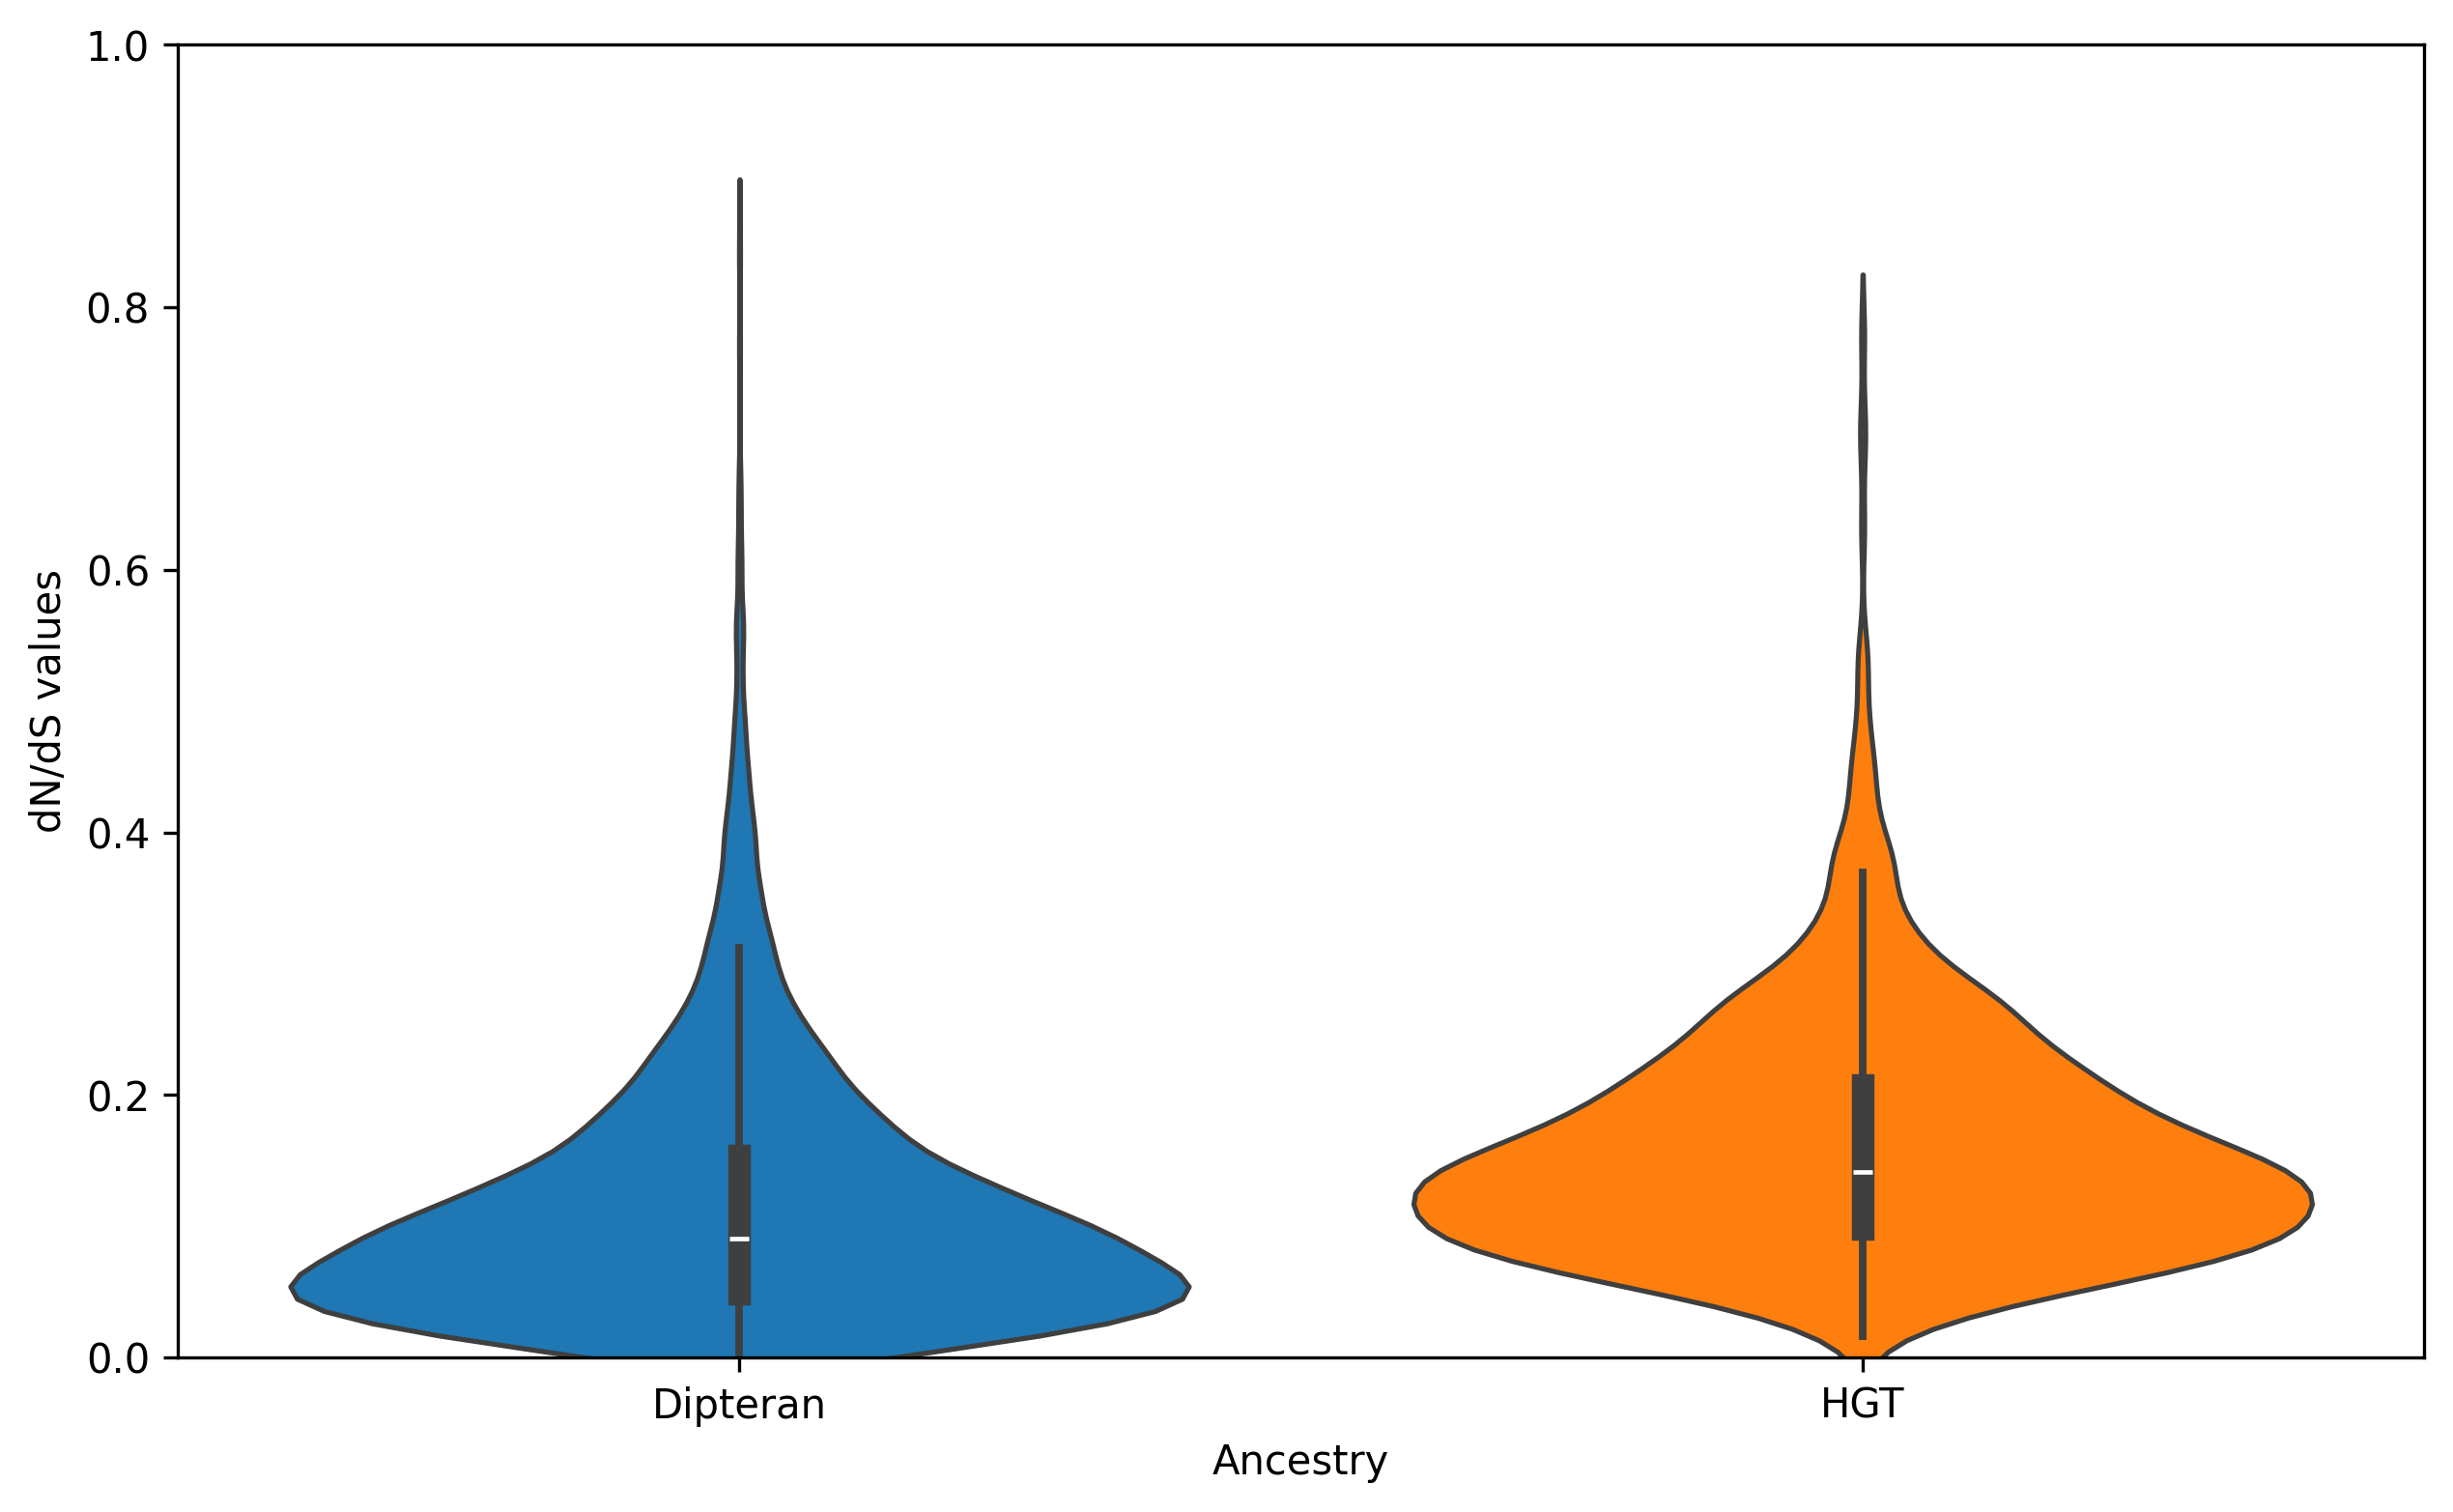

In [58]:

import seaborn as sns
from scipy import stats
import numpy as np
my_pal = {"Dipteran": u'#1f77b4', "HGT": u'#ff7f0e'}

# Sample data (replace this with your actual data)

# Combine the data into a DataFrame for seaborn
data = dNdS[dNdS.type.isin(['Dipteran', 'HGT'])]

# Create a figure
plt.figure(figsize=(10, 6))



dn=list(data[data.type=='Dipteran'].dNdS)
hgt=list(data[data.type=='HGT'].dNdS)


print(np.median(dn),np.median(hgt))
# Perform Mann-Whitney U test
u_statistic, p_value = stats.mannwhitneyu(dn,hgt, alternative='two-sided')
print(u_statistic, p_value)
# Create a violin plot
ax=sns.violinplot(x='type', y='dNdS', data=data,palette=my_pal,saturation=1.0, order= ['Dipteran','HGT'])

# Add labels and title
plt.xlabel('Ancestry')
plt.ylabel('dN/dS values')



plt.ylim(0,1.0)
plt.savefig('figures/dNdS_by_ancestry.svg', format='svg')
# Show the plot
plt.show()


## Include extracellular localization and rna expression level as covariates

In [7]:
di=pd.read_csv("final_outputs/longest_iso_data.csv",index_col=0)
dNdS=pd.read_csv('final_outputs/pairwise_dnds.csv',index_col=0)

In [8]:
import pandas as pd
deeploc=pd.read_csv("final_outputs/deeploc_results.csv",index_col=0)

In [9]:
for index, row in deeploc.iterrows():
    deeploc.loc[index,'gene']=di.loc[index,'gene']

In [10]:
for index, row in dNdS.iterrows():
    dNdS.loc[index,'gene']=di.loc[index,'gene']
    

In [11]:
deeploc=deeploc.set_index('gene')

In [12]:
dftpm=pd.read_csv('final_outputs/rnaseq_tpms.csv',index_col=0)
dftpm=pd.DataFrame(dftpm.mean(axis=1))

In [13]:
dNdS.index=dNdS.gene
for index, row in dNdS.iterrows():
    dNdS.loc[index,'Extracellular']= int('Extracellular' in deeploc.loc[index,'Localizations'])
    dNdS.loc[index,'TPM']= dftpm.loc[index,:].values[0]

In [14]:
import numpy as np
dNdS["logTPM"]=np.log10(dNdS.TPM+1e-2)

In [15]:
dNdS['HGT']=[int(x in set(di[di.tree_HGT].gene)) for x in dNdS.index]

In [16]:
dNdS['dipt']=[int(x in set(di[di.type=='dipt'].gene)) for x in dNdS.index]

In [31]:
prot=di[di.gene==index].index[0]
len(str(bc_fastan[[x for x in bc_fastan if prot in x][0]].seq))

2244

In [32]:
for index, row in dNdS.iterrows():
    prot=di[di.gene==index].index[0]
   
    dNdS.loc[index,'cds_len']=len(str(bc_fastan[[x for x in bc_fastan if prot in x][0]].seq))

In [40]:
dNdS[dNdS.dNdS>=999]

,B.odor,dNdS,lnL,null_lnL,2delta(lnL),p_val,p_val_corrected,type,gene,Extracellular,TPM,logTPM,HGT,dipt,cds_len
gene,,,,,,,,,,,,,,,
LOC119071328,KAG4070650.1,999.0,-469.353011,-470.918934,3.131846,0.076777,0.078936,Dipteran,LOC119071328,1.0,17.425041,1.241423,0,1,360.0


In [41]:
dNdSi=dNdS[(dNdS.dipt==1)|(dNdS.HGT==1)]

In [42]:
dNdS[dNdS.dipt==1].dNdS.median()

0.11338000000000001

In [43]:
dNdS[dNdS.HGT==1].dNdS.median()

0.18163

In [47]:
dNdSi=dNdSi[dNdSi.dNdS<999]

In [64]:
from scipy.stats import mannwhitneyu
print(np.median(dNdSi[dNdSi.HGT==0].cds_len),np.median(dNdSi[dNdSi.HGT==1].cds_len))
print(mannwhitneyu(dNdSi[dNdSi.HGT==0].cds_len,dNdSi[dNdSi.HGT==1].cds_len))

1386.0 1110.0
MannwhitneyuResult(statistic=5370976.0, pvalue=4.466304812180176e-19)


In [65]:
import statsmodels.formula.api as smf 
est = smf.ols(formula='dNdS ~ logTPM+Extracellular+HGT+cds_len', data=dNdSi).fit() 
est.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   dNdS   R-squared:                       0.050
Model:                            OLS   Adj. R-squared:                  0.050
Method:                 Least Squares   F-statistic:                     146.9
Date:                Thu, 02 Apr 2026   Prob (F-statistic):          1.31e-122
Time:                        15:35:55   Log-Likelihood:                 5910.2
No. Observations:               11108   AIC:                        -1.181e+04
Df Residuals:                   11103   BIC:                        -1.177e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         0.1809      0.003     61.678      0.000       0.175       0.187
logTPM           -0.0259      0.002    -14.450      0.000      -0.029      -0.022
Extracellular     0.0567      0.004     14.174      0.000       0.049       0.065
HGT               0.0472      0.005      9.393      0.000       0.037       0.057
cds_len       -2.886e-06   7.86e-07     -3.671      0.000   -4.43e-06   -1.35e-06
==============================================================================
Omnibus:                     5974.456   Durbin-Watson:                   1.986
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            74166.160
Skew:                           2.315   Prob(JB):                         0.00
Kurtosis:                      14.781   Cond. No.                     9.35e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 9.35e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [67]:
est.pvalues

Intercept        0.000000e+00
logTPM           6.656498e-47
Extracellular    3.269146e-45
HGT              6.998979e-21
cds_len          2.426473e-04
dtype: float64

In [18]:
import statsmodels.formula.api as smf 
est = smf.ols(formula='dNdS ~ logTPM+Extracellular+HGT', data=dNdSi).fit() 
est.summary()

/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   dNdS   R-squared:                       0.049
Model:                            OLS   Adj. R-squared:                  0.049
Method:                 Least Squares   F-statistic:                     191.2
Date:                Mon, 29 Dec 2025   Prob (F-statistic):          7.18e-121
Time:                        17:21:41   Log-Likelihood:                 5903.5
No. Observations:               11108   AIC:                        -1.180e+04
Df Residuals:                   11104   BIC:                        -1.177e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         0.1751      0.002     70.849      0.000       0.170       0.180
logTPM           -0.0255      0.002    -14.242      0.000      -0.029      -0.022
Extracellular     0.0579      0.004     14.513      0.000       0.050       0.066
HGT               0.0486      0.005      9.698      0.000       0.039       0.058
==============================================================================
Omnibus:                     5994.494   Durbin-Watson:                   1.988
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            74704.810
Skew:                           2.324   Prob(JB):                         0.00
Kurtosis:                      14.824   Cond. No.                         5.97
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Compare dNdS by ancestry

In [62]:
!cp ../Bradysia_coprophila/deeplocsh.sh ./scripts/deeplocsh.sh

In [6]:
# dftree=pd.read_csv("final_outputs/tree_manual_inspection/manual_inspection_results_with_merging.tsv",sep='\t',index_col=0)
# dNdS=pd.read_csv('final_outputs/pairwise_dnds.csv',index_col=0)

In [57]:
dNdS

,B.impatiens,dNdS,dS,lnL,null_lnL,2delta(lnL),p_val,p_val_corrected,type
B.copro,,,,,,,,,
XP_037034873.1,bimpatiensg26023.t1,0.08932,0.4133,-3485.828667,-3609.950853,248.244372,6.268848e-56,2.777730e-55,Dipteran
XP_080113447.1,bimpatiensg23020.t1,0.11310,0.4901,-2403.825668,-2483.276688,158.902040,1.965823e-36,4.692644e-36,Dipteran
XP_037051514.1,bimpatiensg10366.t1,0.14725,0.4049,-1935.193638,-1983.476099,96.564922,8.636493e-23,1.366062e-22,Dipteran
XP_037028772.1,bimpatiensg17750.t1,0.06291,0.4760,-723.087345,-757.853368,69.532046,7.518302e-17,1.002415e-16,Dipteran
XP_037038973.1,bimpatiensg23908.t1,0.27989,0.7414,-3729.275057,-3785.219090,111.888066,3.780637e-26,6.582833e-26,Dipteran
...,...,...,...,...,...,...,...,...,...
XP_080119071.1,bimpatiensg14062.t1,0.26265,0.5525,-918.086615,-932.407779,28.642328,8.705822e-08,9.377886e-08,Dipteran
XP_037033540.1,bimpatiensg29247.t1,0.34892,0.5226,-5809.352490,-5865.537976,112.370972,2.963358e-26,5.178509e-26,Dipteran
XP_037036517.1,bimpatiensg30876.t1,0.02051,0.5316,-1633.761495,-1748.687327,229.851664,6.422324e-52,2.498424e-51,Dipteran


In [55]:
upsetdf=pd.read_csv('outputs/homologs_in_other_sciarids_per_gene.tsv',sep='\t',index_col=0)
upsetdf

,Bradysia coprophila,Bradysia impatiens,Bradysia odoriphaga,Lycoriella ingenua,Pseudolycoriella hygida,phylostratum
XP_037038926.1,True,False,True,False,True,5.0
XP_037026624.1,True,True,True,True,True,5.0
XP_037034227.1,True,True,True,True,True,5.0
XP_037037850.1,True,True,True,True,True,5.0
XP_037036059.1,True,True,True,True,True,5.0
...,...,...,...,...,...,...
XP_080120532.1,True,False,False,False,False,1.0
XP_080120575.1,True,True,False,False,False,3.0
XP_080120592.1,True,True,False,False,False,3.0
XP_080120593.1,True,True,False,False,False,3.0


In [18]:

import ast
old_seqs=set()
for index, row in dftree[dftree.age_estimate=='old'].iterrows():
    old_seqs=old_seqs|set(ast.literal_eval(row.coprophila_seqs))
mid_seqs=set()
for index, row in dftree[dftree.age_estimate=='mid'].iterrows():
    mid_seqs=mid_seqs|set(ast.literal_eval(row.coprophila_seqs))


In [26]:

orphan=set(di[di.type=='orphan'].index)
dipt=set(di[di.type=='dipt'].index)

In [27]:
dNdS=dNdS[dNdS.dNdS<999]

In [28]:
old_hgt=list(dNdS[dNdS.index.isin(set(old_seqs))].dNdS)
mid_hgt=list(dNdS[dNdS.index.isin(set(mid_seqs))].dNdS)
diptn=list(dNdS[dNdS.index.isin(dipt)].dNdS)
orphann=list(dNdS[dNdS.index.isin(orphan)].dNdS)

In [24]:
len(old_hgt),len(mid_hgt),len(diptn),len(orphann)

(613, 254, 10217, 437)

In [30]:
data = [orphann, mid_hgt, old_hgt, diptn]
names = ['Orphan', 'Mid HGT', 'Old HGT', 'Dipteran']

# Create a two-column DataFrame
df = pd.DataFrame([(value, name) for name, group in zip(names, data) for value in group], columns=['dNdS', 'Ancestry'])


In [31]:
import itertools
import pandas as pd
from scipy.stats import mannwhitneyu

def pairwise_mannwhitney(df, value_col='dNdS', group_col='Ancestry',
                         alternative='two-sided'):
    results = []

    groups = df[group_col].dropna().unique()

    for g1, g2 in itertools.combinations(groups, 2):
        x = df.loc[df[group_col] == g1, value_col].dropna()
        y = df.loc[df[group_col] == g2, value_col].dropna()

        if len(x) > 0 and len(y) > 0:
            stat, p = mannwhitneyu(x, y, alternative=alternative)
        else:
            stat, p = float('nan'), float('nan')

        results.append({
            'group1': g1,
            'group2': g2,
            'U_statistic': stat,
            'p_value': p,
            'n1': len(x),
            'n2': len(y)
        })

    return pd.DataFrame(results)

# usage
mw_results = pairwise_mannwhitney(df)
print(mw_results)


/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


    group1    group2  U_statistic        p_value   n1     n2
0   Orphan   Mid HGT      80876.5   1.120083e-23  437    254
1   Orphan   Old HGT     218838.0   8.895506e-69  437    613
2   Orphan  Dipteran    3819695.0  3.051882e-140  437  10217
3  Mid HGT   Old HGT      98254.0   1.205662e-09  254    613
4  Mid HGT  Dipteran    1897485.5   1.928412e-36  254  10217
5  Old HGT  Dipteran    3964716.0   1.526057e-28  613  10217


In [32]:
summary_df = (
    df
    .dropna(subset=['dNdS', 'Ancestry'])
    .groupby('Ancestry')
    .agg(
        median_dNdS=('dNdS', 'median'),
        n_genes=('dNdS', 'size')
    )
    .reset_index()
)
summary_df

,Ancestry,median_dNdS,n_genes
0,Dipteran,0.113370,10217
1,Mid HGT,0.225445,254
2,Old HGT,0.166500,613
3,Orphan,0.399960,437


In [36]:
plt.rcParams['svg.fonttype'] = 'none'

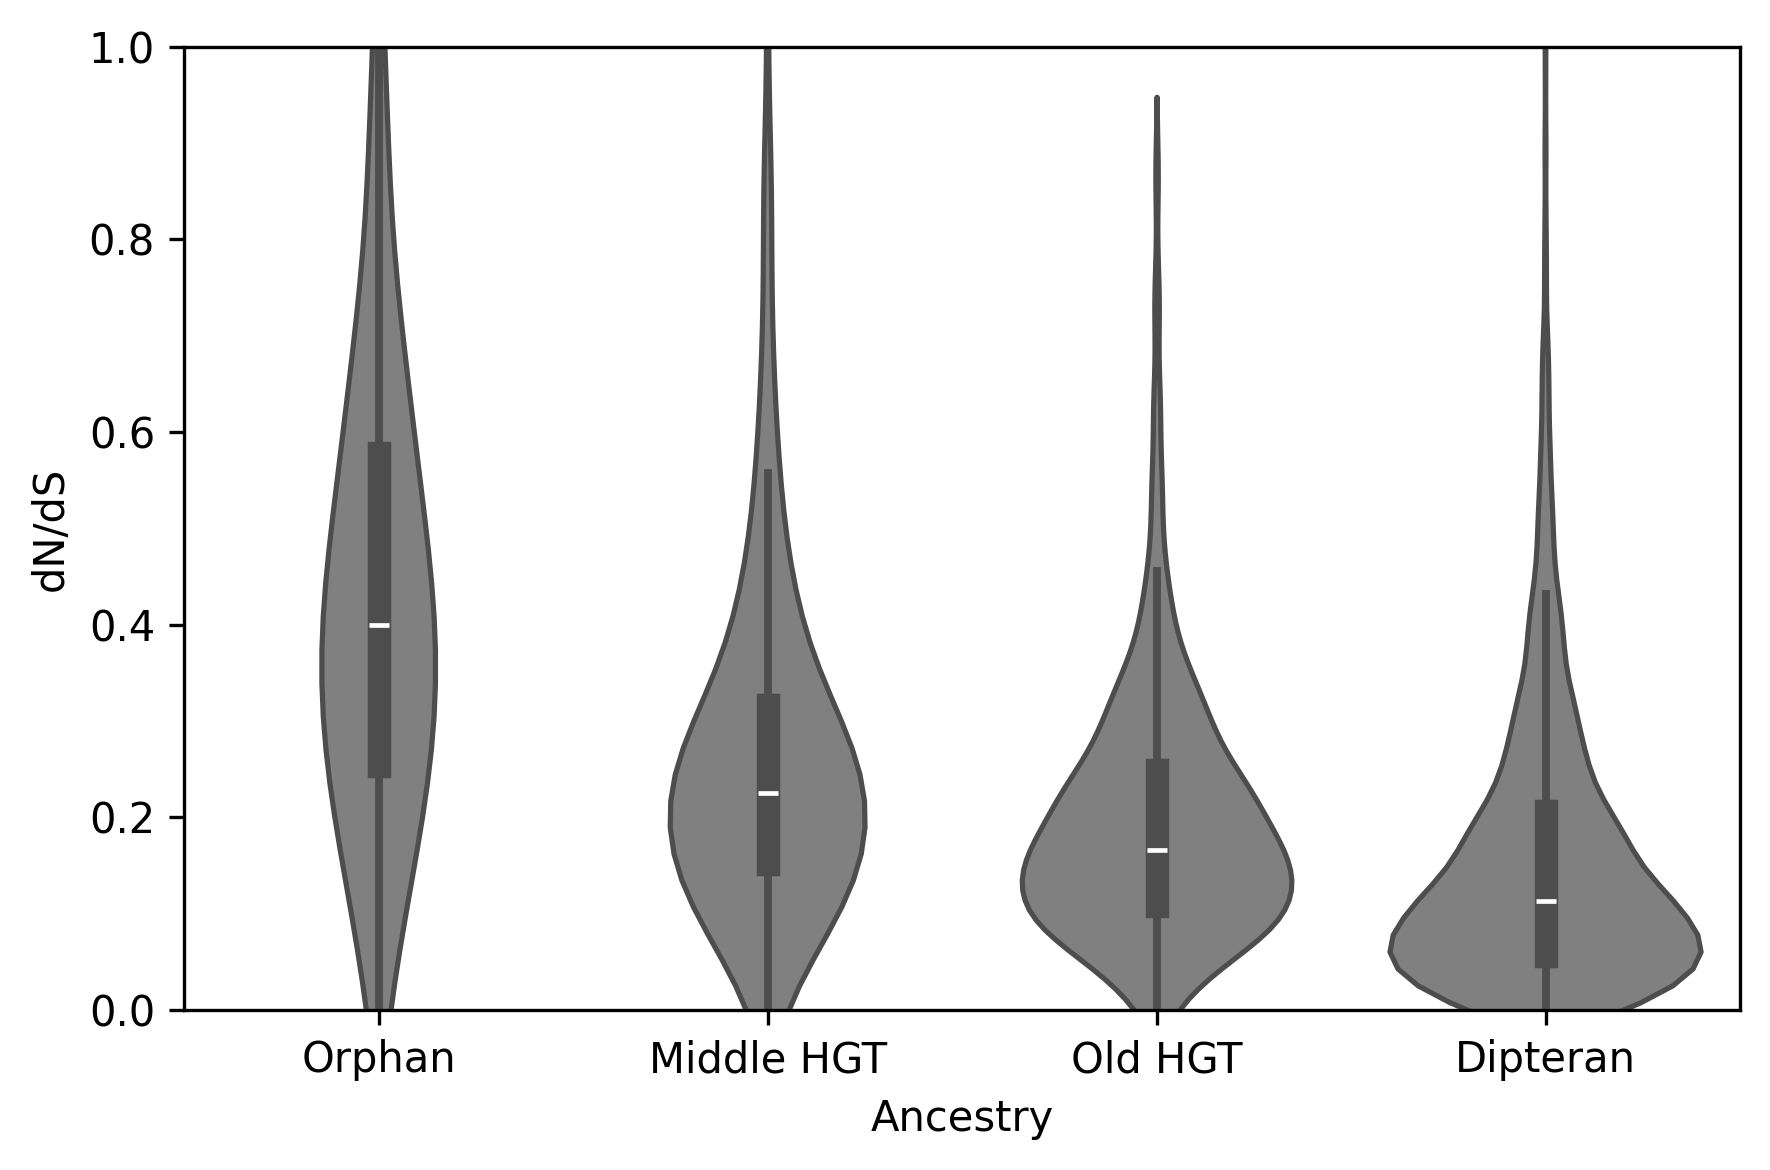

In [39]:
import seaborn as sns

ax=sns.violinplot(data=df, color='grey', x='Ancestry', y='dNdS' 
               )
plt.ylim(0,1)


plt.xticks(ticks=[0, 1, 2,3], labels=['Orphan','Middle HGT', 'Old HGT', 'Dipteran'])
plt.ylabel('dN/dS')


# Show the plot
plt.tight_layout()
plt.savefig('figures/dNdS_pairwise_by_phylostratum.svg',format='svg',bbox_inches='tight')
plt.show()